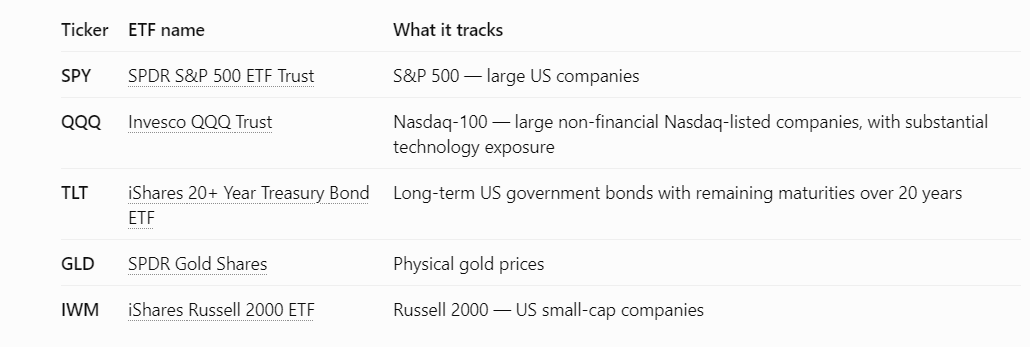

In [2]:
%load_ext autoreload
%autoreload 2

In [34]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import functions
from functions import portfolio_return, portfolio_volatilitycalculation, portfolio_sharpe

prices = pd.read_csv(
    "data/raw/etf_prices.csv",
    index_col=0,
    parse_dates=True
)

Ticker       GLD       IWM       QQQ       SPY       TLT
Ticker                                                  
GLD     1.000000  0.083155  0.090731  0.076267  0.254049
IWM     0.083155  1.000000  0.767181  0.865230 -0.142600
QQQ     0.090731  0.767181  1.000000  0.931869 -0.116654
SPY     0.076267  0.865230  0.931869  1.000000 -0.167927
TLT     0.254049 -0.142600 -0.116654 -0.167927  1.000000


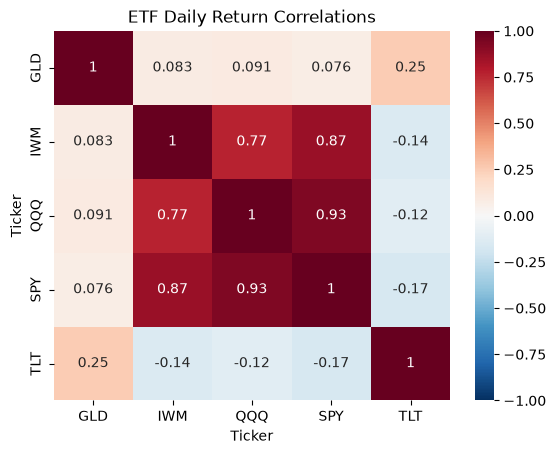

In [4]:
returns = prices.pct_change().dropna()

correlation_matrix = returns.corr()
print(correlation_matrix)
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)
plt.title("ETF Daily Return Correlations")
plt.show()

In [5]:
spy_returns = returns["SPY"]
tlt_returns = returns["TLT"]

rolling_corr = tlt_returns.rolling(100).corr(spy_returns)

In [6]:
portfolios = {
    "SPY": (["SPY"], np.array([1.0])),
    "SPY-GLD": (["SPY", "GLD"], np.array([0.5, 0.5])),
    "SPY-TLT": (["SPY", "TLT"], np.array([0.5, 0.5]))
}

results = []

for name, (tickers, weights) in portfolios.items():

    # Calculate return, volatility and Sharpe ratio
    annual_return = portfolio_return(returns, tickers, weights)
    annual_vol = portfolio_volatilitycalculation(returns, tickers, weights)
    sharpe = portfolio_sharpe(returns, tickers, weights, risk_free_rate=0.03)

    # Store results
    results.append({
        "Portfolio": name,
        "Annual Return": annual_return,
        "Volatility": annual_vol,
        "Sharpe Ratio": sharpe
    })

comparison = pd.DataFrame(results)
print(comparison)

  Portfolio  Annual Return  Volatility  Sharpe Ratio
0       SPY       0.139475    0.175392      0.624175
1   SPY-GLD       0.126850    0.124344      0.778887
2   SPY-TLT       0.070284    0.104621      0.385043


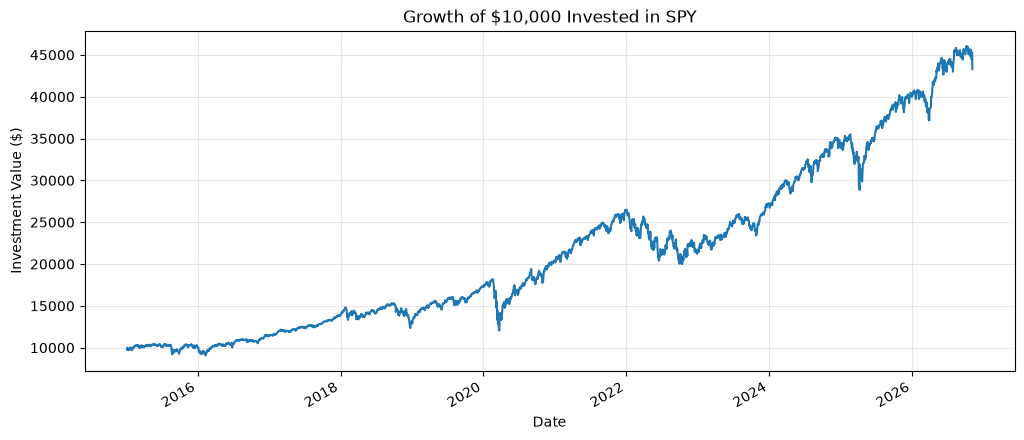

In [7]:
spy_returns = returns["SPY"]
growth_factors = 1 + spy_returns
cumulative_growth = growth_factors.cumprod()
cumulative_growth.head()
initial_investment = 10_000
investment_value = initial_investment*cumulative_growth

investment_value.plot(figsize=(12, 5))

plt.title("Growth of $10,000 Invested in SPY")
plt.xlabel("Date")
plt.ylabel("Investment Value ($)")
plt.grid(alpha=0.3)
plt.show()


In [8]:
weights = np.array([0.5, 0.5])

selected_returns = returns[["SPY", "GLD"]]

portfolio_daily_returns = selected_returns @ weights

portfolio_mdd = functions.maximum_drawdown(portfolio_daily_returns)

print(f"SPY–GLD Maximum Drawdown: {portfolio_mdd:.2%}")




SPY–GLD Maximum Drawdown: -20.32%


In [9]:
portfolios = {
    "SPY": (["SPY"], np.array([1.0])),
    "SPY-GLD": (["SPY", "GLD"], np.array([0.5, 0.5])),
    "SPY-TLT": (["SPY", "TLT"], np.array([0.5, 0.5]))
}


drawdown_results = []

for name, (tickers, weights) in portfolios.items():

    selected_returns = returns[tickers]

    daily_returns = selected_returns @ weights

    mdd = functions.maximum_drawdown(daily_returns)

    # Store results
    drawdown_results.append({
        "Portfolio": name,
        "Maximum Drawdown": mdd
    })

drawdown_comparison = pd.DataFrame(drawdown_results)

drawdown_comparison
  

,Portfolio,Maximum Drawdown
0,SPY,-0.337173
1,SPY-GLD,-0.203151
2,SPY-TLT,-0.284988


In [10]:
final_comparison = pd.merge(
    comparison,
    drawdown_comparison,
    on="Portfolio"
)

# Display percentage columns clearly
final_comparison.style.format({
    "Annual Return": "{:.2%}",
    "Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}"
})
  

,Portfolio,Annual Return,Volatility,Sharpe Ratio,Maximum Drawdown
0,SPY,13.95%,17.54%,0.624,-33.72%
1,SPY-GLD,12.68%,12.43%,0.779,-20.32%
2,SPY-TLT,7.03%,10.46%,0.385,-28.50%


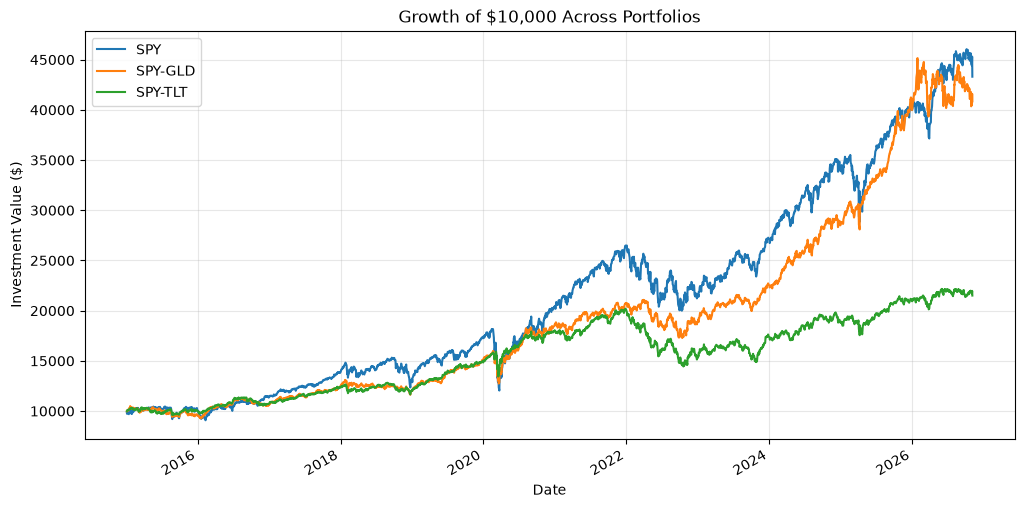

In [11]:
portfolio_values = pd.DataFrame()

for name, (tickers, weights) in portfolios.items():

    selected_returns = returns[tickers]

    daily_returns = selected_returns @ weights

    investment_value = functions.cumulative_performance(daily_returns)

    portfolio_values[name] = investment_value

portfolio_values.plot(figsize=(12, 6))

plt.title("Growth of $10,000 Across Portfolios")
plt.xlabel("Date")
plt.ylabel("Investment Value ($)")
plt.grid(alpha=0.3)
plt.show()


In [12]:
spy_cagr = functions.calculate_cagr(returns["SPY"])

spy_arithmetic = returns["SPY"].mean() * 252

print(f"SPY CAGR: {spy_cagr:.2%}")
print(f"SPY Arithmetic Return: {spy_arithmetic:.2%}")

SPY CAGR: 13.20%
SPY Arithmetic Return: 13.95%


In [13]:
portfolios

{'SPY': (['SPY'], array([1.])),
 'SPY-GLD': (['SPY', 'GLD'], array([0.5, 0.5])),
 'SPY-TLT': (['SPY', 'TLT'], array([0.5, 0.5]))}

In [14]:

cagr_results = []

for name, (tickers, weights) in portfolios.items():

    selected_returns = returns[tickers]

    daily_returns = selected_returns @ weights

    # Calculate CAGR using your existing function
    cagr = functions.calculate_cagr(daily_returns)

    # Store the result
    cagr_results.append({
        "Portfolio": name,
        "CAGR": cagr
    })

cagr_comparison = pd.DataFrame(cagr_results)

cagr_comparison
  

,Portfolio,CAGR
0,SPY,0.132045
1,SPY-GLD,0.126466
2,SPY-TLT,0.066944


In [15]:
updated_comparison = pd.merge(final_comparison, cagr_comparison, on = "Portfolio")
updated_comparison

updated_comparison.style.format({"Annual Return": "{:.2%}", "Volatility": "{:.2%}", "Maximum Drawdown": "{:.2%}", "CAGR": "{:.2%}", "Sharpe Ratio": "{:.3f}"})

,Portfolio,Annual Return,Volatility,Sharpe Ratio,Maximum Drawdown,CAGR
0,SPY,13.95%,17.54%,0.624,-33.72%,13.20%
1,SPY-GLD,12.68%,12.43%,0.779,-20.32%,12.65%
2,SPY-TLT,7.03%,10.46%,0.385,-28.50%,6.69%


In [ ]:

test_returns = pd.DataFrame({
    "ASSET_A": [0.01, -0.01, 0.02, -0.02],
    "ASSET_B": [0.02, 0.01, -0.01, -0.02]
})

invalid_weights = np.array([0.8, 0.8])


try:
    portfolio_volatilitycalculation(
        test_returns,
        ["ASSET_A", "ASSET_B"],
        invalid_weights
    )
except ValueError:
    print("Test passed: invalid weights rejected.")
else:
    raise AssertionError("Invalid weights were accepted!")

AssertionError: 